# BTC–SJC–VN-Index TVP-VAR connectedness

A notebook-first version of this project. It contains the full TVP-VAR(1), GFEVD, connectedness, diagnostics, comparison, and export implementation. Run all cells from the repository root; the only external input is `data/model2_conditional_volatility.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.api import VAR

ROOT = Path.cwd()
if not (ROOT / 'data' / 'model2_conditional_volatility.csv').exists():
    raise FileNotFoundError(
        'Run this notebook with the repository root as the working directory.'
    )

pd.set_option('display.float_format', lambda value: f'{value:,.4f}')

## Model and analysis functions

All project logic is defined in this cell so the notebook has no dependency on `src/`.

In [2]:
from dataclasses import dataclass

import numpy as np
import pandas as pd
from statsmodels.tsa.api import VAR


@dataclass(frozen=True)
class TVPVARResult:
    dates: pd.Index
    variables: tuple[str, ...]
    lambda_beta: float
    kappa_sigma: float
    initial_covariance: float
    coefficients: np.ndarray
    constants: np.ndarray
    shock_covariances: np.ndarray
    innovations: np.ndarray


def estimate_tvp_var(
    data: pd.DataFrame,
    *,
    lambda_beta: float = 0.999,
    kappa_sigma: float = 0.96,
    initial_covariance: float = 0.01,
) -> TVPVARResult:
    """Estimate the project's TVP-VAR(1) forgetting-factor specification."""
    if not 0 < lambda_beta <= 1:
        raise ValueError("lambda_beta must be in (0, 1]")
    if not 0 < kappa_sigma < 1:
        raise ValueError("kappa_sigma must be in (0, 1)")
    if initial_covariance <= 0:
        raise ValueError("initial_covariance must be positive")
    if data.shape[1] < 2 or len(data) < 3:
        raise ValueError("data must contain at least two variables and three rows")
    if data.isna().any().any() or not np.isfinite(data.to_numpy()).all():
        raise ValueError("data contains missing or non-finite values")

    clean = data.astype(float).copy()
    y = clean.to_numpy()
    n_obs, n_vars = y.shape

    static_fit = VAR(clean).fit(maxlags=1, trend="c")
    initial_parameters = static_fit.params.to_numpy()
    regressors_per_equation = n_vars + 1

    beta_previous = initial_parameters.flatten(order="F")
    n_beta = len(beta_previous)
    state_covariance_previous = np.eye(n_beta) * initial_covariance
    sigma_previous = np.asarray(static_fit.sigma_u)

    beta_store = np.zeros((n_obs, n_beta))
    coefficient_store = np.zeros((n_obs, n_vars, n_vars))
    constant_store = np.zeros((n_obs, n_vars))
    sigma_store = np.zeros((n_obs, n_vars, n_vars))
    innovation_store = np.full((n_obs, n_vars), np.nan)

    beta_store[0] = beta_previous
    coefficient_store[0] = initial_parameters[1:, :].T
    constant_store[0] = initial_parameters[0, :]
    sigma_store[0] = sigma_previous

    identity_beta = np.eye(n_beta)

    for t in range(1, n_obs):
        observation_vector = np.concatenate(([1.0], y[t - 1]))
        observation_matrix = np.kron(
            np.eye(n_vars), observation_vector.reshape(1, -1)
        )

        beta_prediction = beta_previous.copy()
        state_covariance_prediction = (
            state_covariance_previous / lambda_beta
        )
        innovation = y[t] - observation_matrix @ beta_prediction
        forecast_covariance = (
            observation_matrix
            @ state_covariance_prediction
            @ observation_matrix.T
            + sigma_previous
            + np.eye(n_vars) * 1e-10
        )
        kalman_gain = (
            state_covariance_prediction
            @ observation_matrix.T
            @ np.linalg.inv(forecast_covariance)
        )
        beta_new = beta_prediction + kalman_gain @ innovation

        gain_observation = kalman_gain @ observation_matrix
        state_covariance_new = (
            (identity_beta - gain_observation)
            @ state_covariance_prediction
            @ (identity_beta - gain_observation).T
            + kalman_gain @ sigma_previous @ kalman_gain.T
        )
        state_covariance_new = (
            state_covariance_new + state_covariance_new.T
        ) / 2

        sigma_new = (
            kappa_sigma * sigma_previous
            + (1 - kappa_sigma) * np.outer(innovation, innovation)
        )
        sigma_new = (sigma_new + sigma_new.T) / 2
        sigma_new += np.eye(n_vars) * 1e-10

        parameter_matrix = beta_new.reshape(
            (regressors_per_equation, n_vars), order="F"
        )
        beta_store[t] = beta_new
        constant_store[t] = parameter_matrix[0, :]
        coefficient_store[t] = parameter_matrix[1:, :].T
        sigma_store[t] = sigma_new
        innovation_store[t] = innovation

        beta_previous = beta_new
        state_covariance_previous = state_covariance_new
        sigma_previous = sigma_new

    return TVPVARResult(
        dates=clean.index,
        variables=tuple(clean.columns),
        lambda_beta=lambda_beta,
        kappa_sigma=kappa_sigma,
        initial_covariance=initial_covariance,
        coefficients=coefficient_store,
        constants=constant_store,
        shock_covariances=sigma_store,
        innovations=innovation_store,
    )

# %%

import numpy as np



def generalized_fevd(model: TVPVARResult, horizon: int = 10) -> np.ndarray:
    """Compute row-normalized generalized FEVD at each time point."""
    if horizon < 1:
        raise ValueError("horizon must be at least 1")

    n_obs, n_vars, _ = model.coefficients.shape
    theta_store = np.zeros((n_obs, n_vars, n_vars))

    for t in range(n_obs):
        coefficient = model.coefficients[t]
        sigma = model.shock_covariances[t]
        moving_average = [
            np.linalg.matrix_power(coefficient, h) for h in range(horizon)
        ]

        theta = np.zeros((n_vars, n_vars))
        for receiver in range(n_vars):
            denominator = sum(
                (phi @ sigma @ phi.T)[receiver, receiver]
                for phi in moving_average
            )
            for shock in range(n_vars):
                numerator = sum(
                    ((phi @ sigma)[receiver, shock]) ** 2
                    for phi in moving_average
                )
                theta[receiver, shock] = (
                    numerator / sigma[shock, shock] / denominator
                )

        row_sums = theta.sum(axis=1, keepdims=True)
        if np.any(row_sums <= 0) or not np.isfinite(row_sums).all():
            raise FloatingPointError(f"Invalid GFEVD row sum at observation {t}")
        theta_store[t] = theta / row_sums

    return theta_store

# %%

from dataclasses import dataclass

import numpy as np
import pandas as pd


@dataclass(frozen=True)
class ConnectednessResult:
    tci: pd.Series
    from_others: pd.DataFrame
    to_others: pd.DataFrame
    net: pd.DataFrame
    theta: np.ndarray

    @property
    def final_table(self) -> pd.DataFrame:
        return pd.DataFrame(
            {
                "FROM": self.from_others.iloc[-1],
                "TO": self.to_others.iloc[-1],
                "NET": self.net.iloc[-1],
            }
        )


def calculate_connectedness(
    theta: np.ndarray,
    *,
    dates: pd.Index,
    variables: tuple[str, ...],
) -> ConnectednessResult:
    if theta.ndim != 3 or theta.shape[1] != theta.shape[2]:
        raise ValueError("theta must have shape (time, variables, variables)")
    if theta.shape[0] != len(dates) or theta.shape[1] != len(variables):
        raise ValueError("theta dimensions do not match dates and variables")
    if not np.isfinite(theta).all():
        raise ValueError("theta contains non-finite values")
    if not np.allclose(theta.sum(axis=2), 1, atol=1e-10):
        raise ValueError("theta rows must sum to one")

    diagonal = np.diagonal(theta, axis1=1, axis2=2)
    from_others = (theta.sum(axis=2) - diagonal) * 100
    to_others = (theta.sum(axis=1) - diagonal) * 100
    net = to_others - from_others
    tci = from_others.sum(axis=1) / theta.shape[1]

    return ConnectednessResult(
        tci=pd.Series(tci, index=dates, name="TCI"),
        from_others=pd.DataFrame(from_others, index=dates, columns=variables),
        to_others=pd.DataFrame(to_others, index=dates, columns=variables),
        net=pd.DataFrame(net, index=dates, columns=variables),
        theta=theta,
    )

# %%

import numpy as np
import pandas as pd



def stability_table(model: TVPVARResult) -> pd.DataFrame:
    radius = np.array(
        [np.max(np.abs(np.linalg.eigvals(matrix))) for matrix in model.coefficients]
    )
    return pd.DataFrame(
        {"spectral_radius": radius, "stable": radius < 1},
        index=model.dates,
    )


def unstable_episodes(table: pd.DataFrame) -> pd.DataFrame:
    unstable = table.loc[~table["stable"]].copy()
    if unstable.empty:
        return pd.DataFrame(columns=["start", "end", "duration", "max_radius"])

    positions = np.flatnonzero(~table["stable"].to_numpy())
    unstable["position"] = positions
    unstable["episode"] = unstable["position"].diff().ne(1).cumsum()

    records = []
    for _, group in unstable.groupby("episode"):
        records.append(
            {
                "start": group.index[0],
                "end": group.index[-1],
                "duration": len(group),
                "max_radius": group["spectral_radius"].max(),
            }
        )
    return pd.DataFrame(records)


def instability_context(
    table: pd.DataFrame,
    tci: pd.Series,
    net: pd.DataFrame,
) -> pd.DataFrame:
    """Combine unstable dates with connectedness measures for interpretation."""
    if not table.index.equals(tci.index) or not table.index.equals(net.index):
        raise ValueError("stability and connectedness indices must match")
    context = table.loc[~table["stable"]].copy()
    context["TCI"] = tci.loc[context.index]
    for variable in net.columns:
        context[f"NET_{variable}"] = net.loc[context.index, variable]
    return context

# %%

from dataclasses import dataclass

import pandas as pd



@dataclass(frozen=True)
class SpecificationResult:
    name: str
    horizon: int
    model: TVPVARResult
    stability: pd.DataFrame
    episodes: pd.DataFrame
    connectedness: ConnectednessResult

    def summary(self) -> pd.Series:
        result = {
            "lambda_beta": self.model.lambda_beta,
            "kappa_sigma": self.model.kappa_sigma,
            "horizon": self.horizon,
            "stable_share": self.stability["stable"].mean(),
            "unstable_periods": int((~self.stability["stable"]).sum()),
            "max_spectral_radius": self.stability["spectral_radius"].max(),
            "mean_tci": self.connectedness.tci.mean(),
            "final_tci": self.connectedness.tci.iloc[-1],
        }
        result.update(
            {
                f"mean_net_{variable}": value
                for variable, value in self.connectedness.net.mean().items()
            }
        )
        result.update(
            {
                f"final_net_{variable}": value
                for variable, value in self.connectedness.net.iloc[-1].items()
            }
        )
        return pd.Series(result, name=self.name)


def run_specification(
    data: pd.DataFrame,
    *,
    name: str,
    lambda_beta: float,
    kappa_sigma: float = 0.96,
    initial_covariance: float = 0.01,
    horizon: int = 10,
) -> SpecificationResult:
    model = estimate_tvp_var(
        data,
        lambda_beta=lambda_beta,
        kappa_sigma=kappa_sigma,
        initial_covariance=initial_covariance,
    )
    stability = stability_table(model)
    theta = generalized_fevd(model, horizon=horizon)
    connectedness = calculate_connectedness(
        theta, dates=model.dates, variables=model.variables
    )
    return SpecificationResult(
        name=name,
        horizon=horizon,
        model=model,
        stability=stability,
        episodes=unstable_episodes(stability),
        connectedness=connectedness,
    )


def compare_specifications(
    specifications: list[SpecificationResult],
) -> pd.DataFrame:
    if not specifications:
        raise ValueError("at least one specification is required")
    return pd.DataFrame([result.summary() for result in specifications])

# %%

from pathlib import Path

import numpy as np
import pandas as pd



VARIABLES = ("BTC", "SJC", "VNINDEX")


def load_volatility_data(path: str | Path) -> pd.DataFrame:
    data = pd.read_csv(path, parse_dates=["Date"])
    data = (
        data.sort_values("Date")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
        .set_index("Date")
    )
    if tuple(data.columns) != VARIABLES:
        raise ValueError(f"expected columns {VARIABLES}, got {tuple(data.columns)}")
    if not data.index.is_monotonic_increasing:
        raise ValueError("dates must be monotonically increasing")
    return data.astype(float)


def save_results(result: SpecificationResult, directory: str | Path) -> None:
    output = Path(directory)
    output.mkdir(parents=True, exist_ok=True)
    result.connectedness.tci.to_csv(output / "tci.csv", header=True)
    result.connectedness.from_others.to_csv(output / "from.csv")
    result.connectedness.to_others.to_csv(output / "to.csv")
    result.connectedness.net.to_csv(output / "net.csv")
    result.stability.to_csv(output / "stability.csv")
    result.episodes.to_csv(output / "unstable_episodes.csv", index=False)
    instability_context(
        result.stability,
        result.connectedness.tci,
        result.connectedness.net,
    ).to_csv(output / "unstable_observations.csv")
    result.summary().to_frame("value").to_csv(output / "summary.csv")


def save_comparison(
    results: list[SpecificationResult], path: str | Path
) -> None:
    output = Path(path)
    output.parent.mkdir(parents=True, exist_ok=True)
    compare_specifications(results).to_csv(output)

## Load data and run the six specifications

In [3]:
data = load_volatility_data(ROOT / 'data' / 'model2_conditional_volatility.csv')
display(data.head())

specifications = [
    {'name': 'baseline_0999', 'lambda_beta': 0.999, 'kappa_sigma': 0.96, 'horizon': 10},
    {'name': 'robustness_0997', 'lambda_beta': 0.997, 'kappa_sigma': 0.96, 'horizon': 10},
    {'name': 'kappa_094', 'lambda_beta': 0.999, 'kappa_sigma': 0.94, 'horizon': 10},
    {'name': 'kappa_098', 'lambda_beta': 0.999, 'kappa_sigma': 0.98, 'horizon': 10},
    {'name': 'horizon_05', 'lambda_beta': 0.999, 'kappa_sigma': 0.96, 'horizon': 5},
    {'name': 'horizon_20', 'lambda_beta': 0.999, 'kappa_sigma': 0.96, 'horizon': 20},
]

results = {
    specification['name']: run_specification(data, initial_covariance=0.01, **specification)
    for specification in specifications
}
comparison = compare_specifications(list(results.values()))
comparison

,BTC,SJC,VNINDEX
Date,,,
2023-08-02,2.2769,0.2109,1.2099
2023-08-03,2.3912,0.2114,1.1009
2023-08-04,2.3084,0.2283,1.1604
2023-08-07,2.2678,0.2331,1.1205
2023-08-08,2.1970,0.2323,1.0754


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


,lambda_beta,kappa_sigma,horizon,stable_share,unstable_periods,max_spectral_radius,mean_tci,final_tci,mean_net_BTC,mean_net_SJC,mean_net_VNINDEX,final_net_BTC,final_net_SJC,final_net_VNINDEX
baseline_0999,0.9990,0.9600,10.0000,0.9813,14.0000,1.0269,7.9241,2.2449,2.8759,2.2210,-5.0969,-1.5648,1.9368,-0.3720
robustness_0997,0.9970,0.9600,10.0000,0.9398,45.0000,1.0293,8.8811,2.0017,2.2284,1.7012,-3.9296,-1.6817,0.2730,1.4087
kappa_094,0.9990,0.9400,10.0000,0.9746,19.0000,1.0263,9.4555,1.6385,3.4442,3.1780,-6.6222,-1.5482,1.1285,0.4197
kappa_098,0.9990,0.9800,10.0000,0.9893,8.0000,1.0294,5.9812,3.4131,1.4519,1.1489,-2.6009,-2.3392,1.1990,1.1402
horizon_05,0.9990,0.9600,5.0000,0.9813,14.0000,1.0269,5.0289,0.9167,1.5441,0.6832,-2.2273,-0.4456,0.2891,0.1565
horizon_20,0.9990,0.9600,20.0000,0.9813,14.0000,1.0269,13.2622,5.5463,3.5959,5.7484,-9.3443,-4.0812,7.0585,-2.9773


## Robustness and horizon comparisons

In [4]:
display(comparison.loc[['baseline_0999', 'robustness_0997', 'kappa_094', 'kappa_098']])
display(comparison.loc[['horizon_05', 'baseline_0999', 'horizon_20']])

,lambda_beta,kappa_sigma,horizon,stable_share,unstable_periods,max_spectral_radius,mean_tci,final_tci,mean_net_BTC,mean_net_SJC,mean_net_VNINDEX,final_net_BTC,final_net_SJC,final_net_VNINDEX
baseline_0999,0.9990,0.9600,10.0000,0.9813,14.0000,1.0269,7.9241,2.2449,2.8759,2.2210,-5.0969,-1.5648,1.9368,-0.3720
robustness_0997,0.9970,0.9600,10.0000,0.9398,45.0000,1.0293,8.8811,2.0017,2.2284,1.7012,-3.9296,-1.6817,0.2730,1.4087
kappa_094,0.9990,0.9400,10.0000,0.9746,19.0000,1.0263,9.4555,1.6385,3.4442,3.1780,-6.6222,-1.5482,1.1285,0.4197
kappa_098,0.9990,0.9800,10.0000,0.9893,8.0000,1.0294,5.9812,3.4131,1.4519,1.1489,-2.6009,-2.3392,1.1990,1.1402


,lambda_beta,kappa_sigma,horizon,stable_share,unstable_periods,max_spectral_radius,mean_tci,final_tci,mean_net_BTC,mean_net_SJC,mean_net_VNINDEX,final_net_BTC,final_net_SJC,final_net_VNINDEX
horizon_05,0.9990,0.9600,5.0000,0.9813,14.0000,1.0269,5.0289,0.9167,1.5441,0.6832,-2.2273,-0.4456,0.2891,0.1565
baseline_0999,0.9990,0.9600,10.0000,0.9813,14.0000,1.0269,7.9241,2.2449,2.8759,2.2210,-5.0969,-1.5648,1.9368,-0.3720
horizon_20,0.9990,0.9600,20.0000,0.9813,14.0000,1.0269,13.2622,5.5463,3.5959,5.7484,-9.3443,-4.0812,7.0585,-2.9773


## Local-stability diagnostics

In [5]:
baseline = results['baseline_0999']
unstable = baseline.stability.loc[~baseline.stability['stable']]
unstable_tci = baseline.connectedness.tci.loc[unstable.index]
stable_tci = baseline.connectedness.tci.loc[baseline.stability['stable']]

print(f'Unstable observations: {len(unstable)}')
print(f'Unstable episodes: {len(baseline.episodes)}')
print(f'Mean TCI on unstable dates: {unstable_tci.mean():.4f}%')
print(f'Mean TCI on stable dates: {stable_tci.mean():.4f}%')
display(baseline.episodes)
display(instability_context(baseline.stability, baseline.connectedness.tci, baseline.connectedness.net))

Unstable observations: 14
Unstable episodes: 3
Mean TCI on unstable dates: 14.7108%
Mean TCI on stable dates: 7.7945%


,start,end,duration,max_radius
0,2023-11-29,2023-11-29,1,1.0134
1,2023-12-26,2024-01-10,11,1.0269
2,2024-01-15,2024-01-16,2,1.0030


,spectral_radius,stable,TCI,NET_BTC,NET_SJC,NET_VNINDEX
Date,,,,,,
2023-11-29,1.0134,False,15.4991,-9.6423,-13.0434,22.6857
2023-12-26,1.0159,False,12.1376,-0.6468,14.5494,-13.9026
2023-12-27,1.0108,False,12.8632,-2.0135,16.8093,-14.7958
2023-12-28,1.0051,False,12.5010,0.1047,17.0259,-17.1306
2023-12-29,1.0220,False,14.7012,-2.3608,24.4451,-22.0843
2024-01-02,1.0269,False,15.3336,-2.9873,26.1406,-23.1532
2024-01-03,1.0177,False,15.8452,-3.8242,28.0524,-24.2282
2024-01-04,1.0171,False,16.7625,-5.2890,28.8865,-23.5975
2024-01-05,1.0120,False,15.8031,-3.2701,28.5623,-25.2922


## Time-varying connectedness

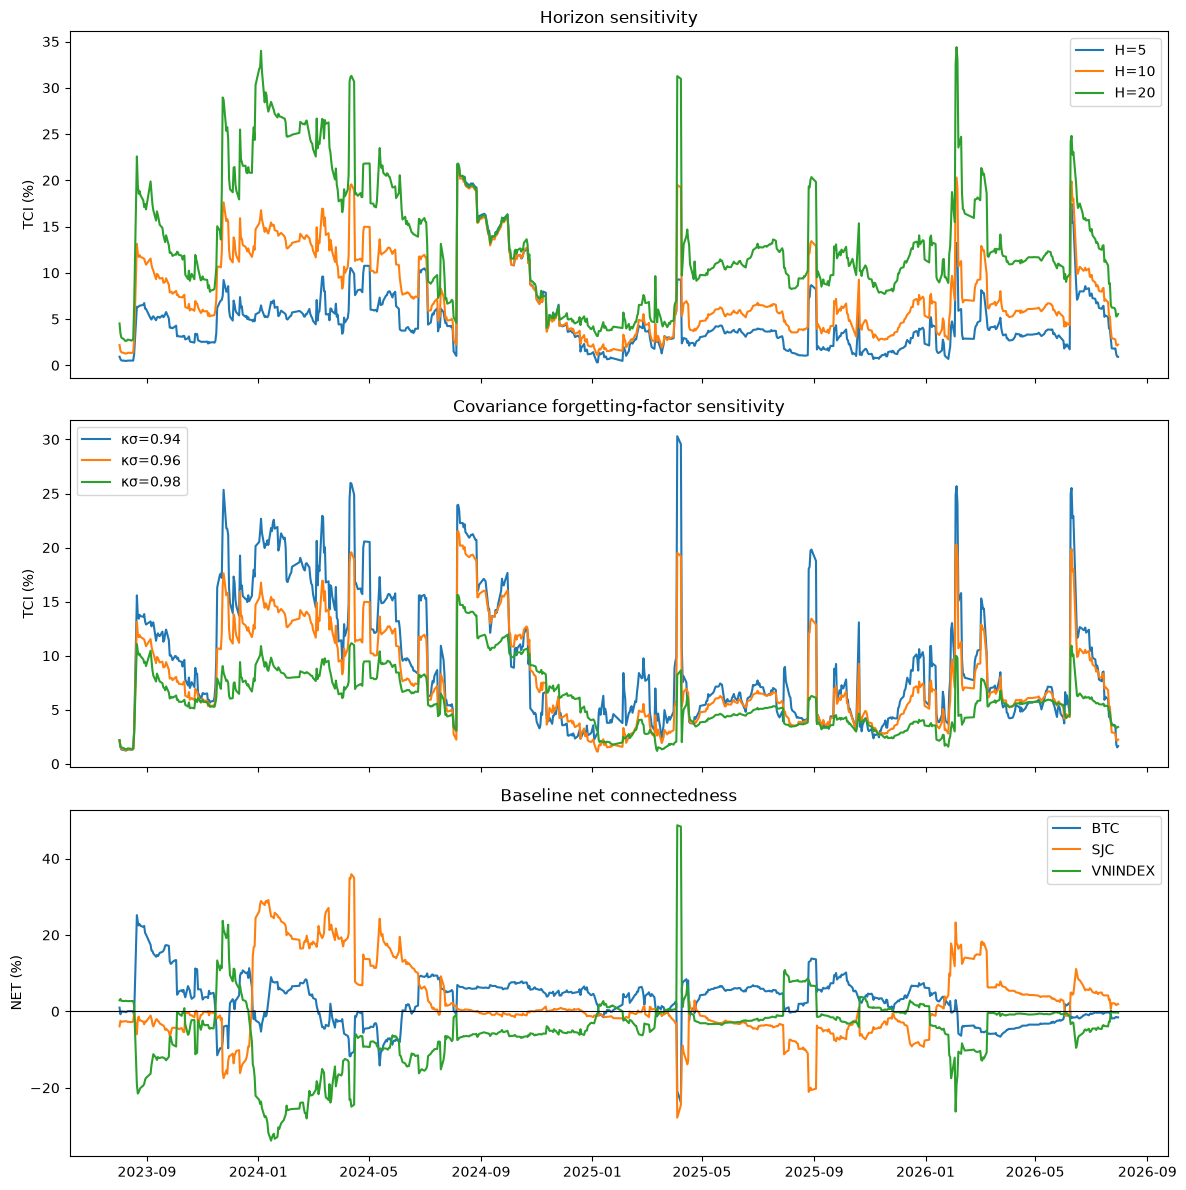

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

for key in ['horizon_05', 'baseline_0999', 'horizon_20']:
    result = results[key]
    axes[0].plot(result.connectedness.tci, label=f'H={result.horizon}')
axes[0].set(title='Horizon sensitivity', ylabel='TCI (%)')
axes[0].legend()

for key in ['kappa_094', 'baseline_0999', 'kappa_098']:
    result = results[key]
    axes[1].plot(result.connectedness.tci, label=f"κσ={result.model.kappa_sigma}")
axes[1].set(title='Covariance forgetting-factor sensitivity', ylabel='TCI (%)')
axes[1].legend()

for variable in baseline.model.variables:
    axes[2].plot(baseline.connectedness.net[variable], label=variable)
axes[2].axhline(0, color='black', linewidth=0.8)
axes[2].set(title='Baseline net connectedness', ylabel='NET (%)')
axes[2].legend()
fig.tight_layout()
plt.show()

## Save reproducible outputs

Set `WRITE_OUTPUTS` to `False` if you only want to inspect results.

In [7]:
WRITE_OUTPUTS = True

if WRITE_OUTPUTS:
    for result in results.values():
        save_results(result, ROOT / 'outputs' / result.name)
    save_comparison(list(results.values()), ROOT / 'outputs' / 'specification_comparison.csv')
    print('Saved outputs/')

Saved outputs/


## Interpretation

Use the comparison table for full-sample average and final-period measures. Positive NET denotes a net transmitter, while negative NET denotes a net receiver. The stability table flags local coefficient matrices with spectral radius at least one; finite-horizon GFEVD results are retained and reported alongside that diagnostic.